# Persiapan Pemodelan SARIMA: Pembagian Data, Baseline Naif Musiman, ACF dan PACF

In [3]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [4]:
PATH = "C:\\Users\\Aurel Maritza\\OneDrive\\ドキュメント\\A. KULIAH\\SEM 5\\ADW\\Harian_Total_2023_sd_2026.xlsx"
KOLOM = "jk"
MUSIM = 7
UJI_HARI = 57
AKHIR = "2026-10-12"

df = pd.read_excel(PATH)
df["tanggal"] = pd.to_datetime(df["tanggal"])
y = df.set_index("tanggal")[KOLOM].asfreq("D").loc[:AKHIR]

print(y.shape, y.index.min().date(), y.index.max().date(), y.isna().sum())

(1381,) 2023-01-01 2026-10-12 0


## Pembagian data latih dan uji

In [5]:
latih = y.iloc[:-UJI_HARI]
uji = y.iloc[-UJI_HARI:]

pembagian = pd.DataFrame({
    "Data": ["Latih", "Uji"],
    "Mulai": [latih.index.min().date(), uji.index.min().date()],
    "Selesai": [latih.index.max().date(), uji.index.max().date()],
    "Jumlah hari": [len(latih), len(uji)],
    "Persentase": [round(len(latih) / len(y) * 100, 1), round(len(uji) / len(y) * 100, 1)],
})
pembagian

,Data,Mulai,Selesai,Jumlah hari,Persentase
0,Latih,2023-01-01,2026-08-16,1324,95.9
1,Uji,2026-08-17,2026-10-12,57,4.1


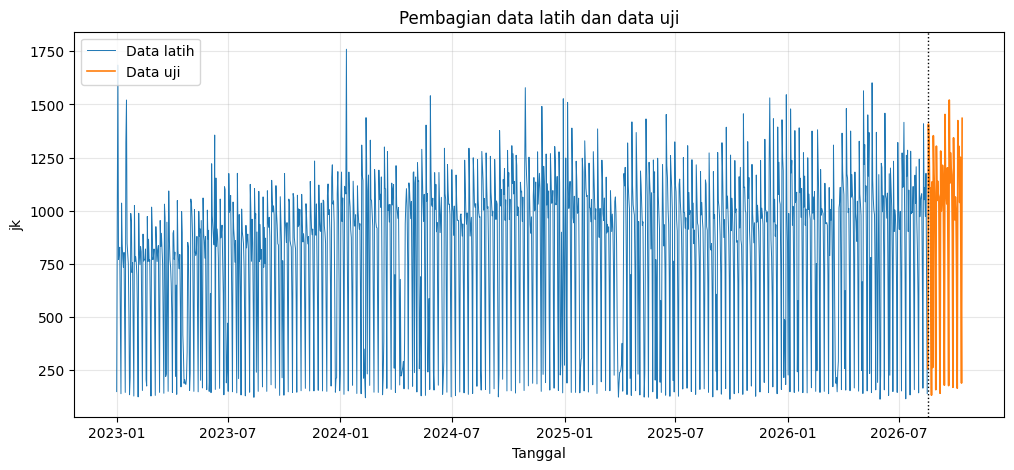

In [6]:
fig, ax = plt.subplots()
ax.plot(latih.index, latih.values, color="#1f77b4", lw=0.7, label="Data latih")
ax.plot(uji.index, uji.values, color="#ff7f0e", lw=1.2, label="Data uji")
ax.axvline(uji.index.min(), color="k", ls=":", lw=1)
ax.set_title("Pembagian data latih dan data uji")
ax.set_xlabel("Tanggal")
ax.set_ylabel(KOLOM)
ax.legend(loc="upper left")
plt.show()

## Stasioneritas data latih setelah differencing

In [7]:
def kesimpulan(p, h0_stasioner):
    if h0_stasioner:
        return "Tolak H0, tidak stasioner" if p < 0.05 else "Gagal tolak H0, stasioner"
    return "Tolak H0, stasioner" if p < 0.05 else "Gagal tolak H0, tidak stasioner"


def uji_stasioneritas(seri, nama):
    seri = seri.dropna()
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(seri, autolag="AIC")
    kpss_stat, kpss_p, _, kpss_crit = kpss(seri, regression="c", nlags="auto")
    return [
        [nama, "ADF", "Ada unit root (tidak stasioner)", adf_stat, adf_crit["5%"], adf_p, kesimpulan(adf_p, False)],
        [nama, "KPSS (level)", "Stasioner di sekitar level", kpss_stat, kpss_crit["5%"], kpss_p, kesimpulan(kpss_p, True)],
    ]


diff_musiman = latih.diff(MUSIM).dropna()
diff_musiman_reguler = diff_musiman.diff(1).dropna()

kolom = ["Data latih", "Uji", "Hipotesis nol (H0)", "Statistik uji", "Nilai kritis 5%", "p-value", "Kesimpulan"]
baris = uji_stasioneritas(diff_musiman, f"Diff musiman lag {MUSIM} (D=1, d=0)") + uji_stasioneritas(diff_musiman_reguler, f"Diff musiman lag {MUSIM} + diff lag 1 (D=1, d=1)")
pd.DataFrame(baris, columns=kolom).round(4)

,Data latih,Uji,Hipotesis nol (H0),Statistik uji,Nilai kritis 5%,p-value,Kesimpulan
0,"Diff musiman lag 7 (D=1, d=0)",ADF,Ada unit root (tidak stasioner),-12.8392,-2.8638,0.0,"Tolak H0, stasioner"
1,"Diff musiman lag 7 (D=1, d=0)",KPSS (level),Stasioner di sekitar level,0.0061,0.4630,0.1,"Gagal tolak H0, stasioner"
2,"Diff musiman lag 7 + diff lag 1 (D=1, d=1)",ADF,Ada unit root (tidak stasioner),-14.1808,-2.8638,0.0,"Tolak H0, stasioner"
3,"Diff musiman lag 7 + diff lag 1 (D=1, d=1)",KPSS (level),Stasioner di sekitar level,0.0376,0.4630,0.1,"Gagal tolak H0, stasioner"


## Plot ACF dan PACF

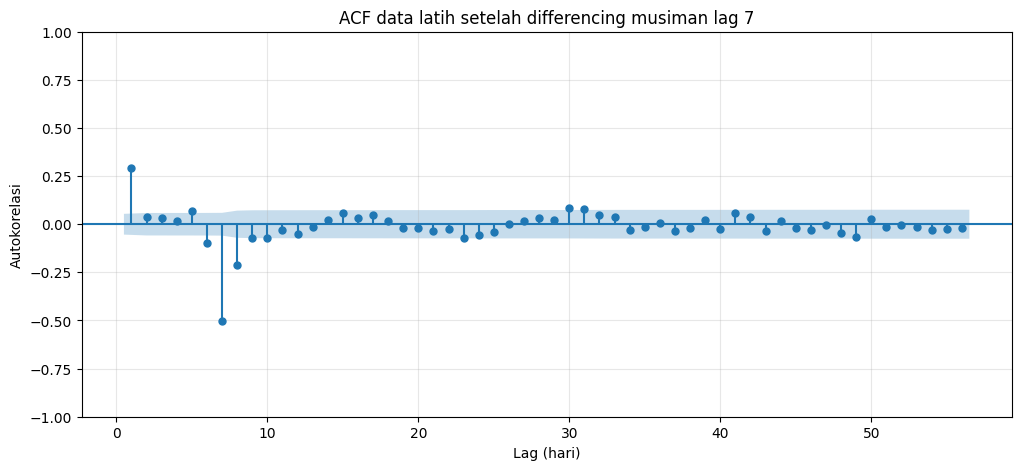

In [8]:
fig, ax = plt.subplots()
plot_acf(diff_musiman, lags=56, ax=ax, zero=False)
ax.set_title(f"ACF data latih setelah differencing musiman lag {MUSIM}")
ax.set_xlabel("Lag (hari)")
ax.set_ylabel("Autokorelasi")
plt.show()

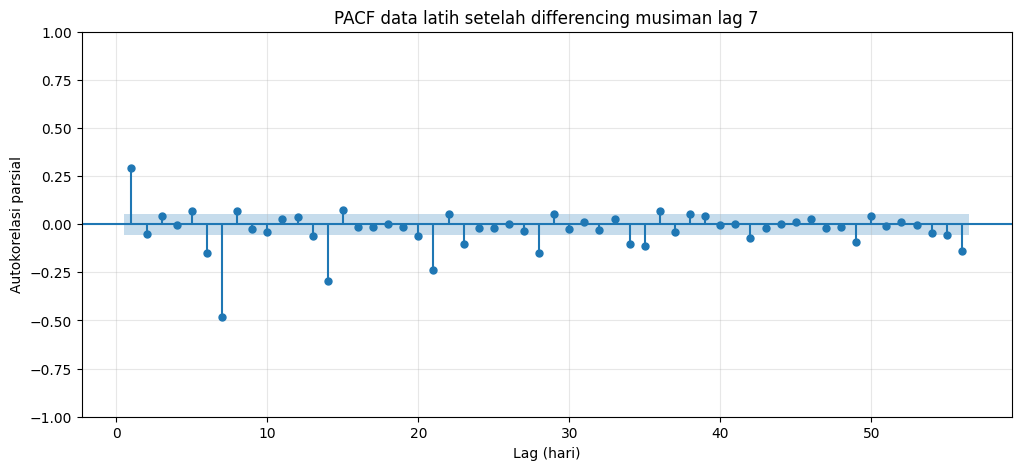

In [9]:
fig, ax = plt.subplots()
plot_pacf(diff_musiman, lags=56, ax=ax, zero=False, method="ywm")
ax.set_title(f"PACF data latih setelah differencing musiman lag {MUSIM}")
ax.set_xlabel("Lag (hari)")
ax.set_ylabel("Autokorelasi parsial")
plt.show()

## Kandidat model SARIMA

In [10]:
kandidat = [
    ((1, 0, 0), (0, 1, 1, MUSIM)),
    ((0, 0, 1), (0, 1, 1, MUSIM)),
    ((1, 0, 1), (0, 1, 1, MUSIM)),
    ((2, 0, 0), (0, 1, 1, MUSIM)),
    ((1, 0, 0), (1, 1, 1, MUSIM)),
    ((0, 1, 1), (0, 1, 1, MUSIM)),
]

tabel_kandidat = pd.DataFrame(
    [[i + 1, f"SARIMA{o}{so}", o, so] for i, (o, so) in enumerate(kandidat)],
    columns=["No", "Model", "Orde (p,d,q)", "Orde musiman (P,D,Q,s)"],
)
tabel_kandidat

,No,Model,"Orde (p,d,q)","Orde musiman (P,D,Q,s)"
0,1,"SARIMA(1, 0, 0)(0, 1, 1, 7)","(1, 0, 0)","(0, 1, 1, 7)"
1,2,"SARIMA(0, 0, 1)(0, 1, 1, 7)","(0, 0, 1)","(0, 1, 1, 7)"
2,3,"SARIMA(1, 0, 1)(0, 1, 1, 7)","(1, 0, 1)","(0, 1, 1, 7)"
3,4,"SARIMA(2, 0, 0)(0, 1, 1, 7)","(2, 0, 0)","(0, 1, 1, 7)"
4,5,"SARIMA(1, 0, 0)(1, 1, 1, 7)","(1, 0, 0)","(1, 1, 1, 7)"
5,6,"SARIMA(0, 1, 1)(0, 1, 1, 7)","(0, 1, 1)","(0, 1, 1, 7)"


## Baseline naif musiman

In [11]:
pola_terakhir = latih.values[-MUSIM:]
prediksi_naif = pd.Series(np.resize(pola_terakhir, UJI_HARI), index=uji.index)

penyebut_mase = latih.diff(MUSIM).abs().dropna().mean()

mae = np.mean(np.abs(uji - prediksi_naif))
rmse = np.sqrt(np.mean((uji - prediksi_naif) ** 2))
mase = mae / penyebut_mase

hasil_naif = pd.DataFrame(
    {"MAE": [mae], "RMSE": [rmse], "MASE": [mase]},
    index=["Naif musiman"],
)
print(f"Penyebut MASE (rata-rata selisih absolut musiman data latih): {penyebut_mase:.2f}")
hasil_naif.round(2)

Penyebut MASE (rata-rata selisih absolut musiman data latih): 164.45


,MAE,RMSE,MASE
Naif musiman,123.42,220.48,0.75


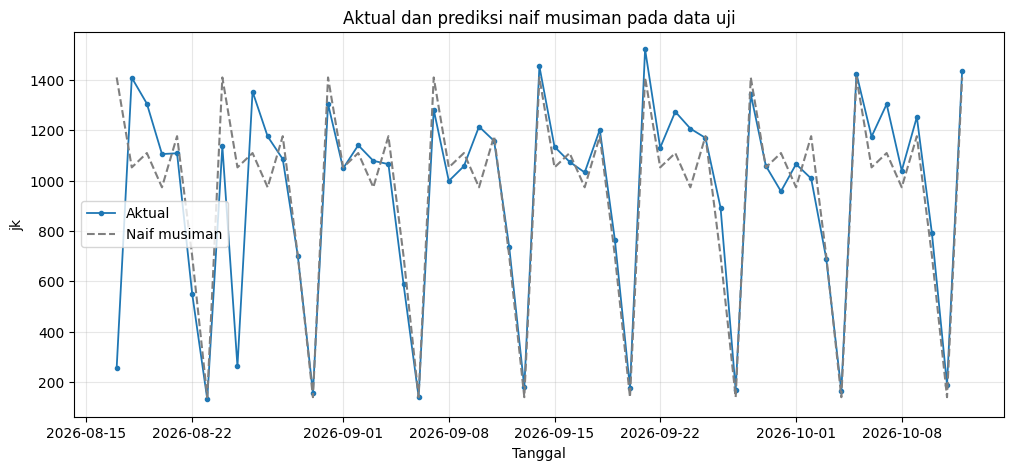

In [12]:
fig, ax = plt.subplots()
ax.plot(uji.index, uji.values, color="#1f77b4", marker="o", ms=3, lw=1.3, label="Aktual")
ax.plot(prediksi_naif.index, prediksi_naif.values, color="#7f7f7f", ls="--", lw=1.5, label="Naif musiman")
ax.set_title("Aktual dan prediksi naif musiman pada data uji")
ax.set_xlabel("Tanggal")
ax.set_ylabel(KOLOM)
ax.legend()
plt.show()